# Create Easy Dataset

In this notebook, we generate a simulated "easy" EEG dataset. The simulation includes a signal for active dipoles and a background signal. The user can define a range for the number of dipoles with the active signal, and the remaining dipoles will contain only the background signal. Additionally, the user can select a range for the EEG signal-to-noise ratio (SNR), so that the variance of the background signal is adjusted to ensure the EEG SNR falls within the specified range.

I have divided this notebook into three sections:

1. Visualize the head model to be used.
2. Inspect the simulation model and determine the appropriate ranges for the number of dipoles and EEG SNR.
3. Generate the dataset.

For each section, you will need to run the '📦 Imports' and '🧠 Data' cells first. After that, the three sections are independent of each other.

## 📦 Imports

In [1]:
import mindmap as mm 
import pyvista as pv
import pywt
import numpy as np
import mne
import seaborn as sns
import pandas as pd
import plotly.express as px

## 🧠 Data

In [2]:
# configuration
sub = "vepcon_sub-10"
mm.io.read_config("../configurations/simf.yml")

data  = mm.io.read_dataset(sub, "eeg_coreg", "fwd_hr", "parc", "cras", "white", "bem")
sfreq = data["eeg_coreg"].info["sfreq"]

# parameters
duration = 1    # duration in seconds

## Section 1: Visualize Head Model

#### 🌟 EEG Coregistration

In [148]:
pos  = mm.utils.get_ch_positions(data["eeg_coreg"])
head = data["bem"][0]

plotter = pv.Plotter()
plotter.add_mesh(pv.PolyData(pos), color="red")
plotter.add_mesh(mm.utils.surf_to_polydata(head["rr"], head["tris"]))
plotter.show()

Widget(value='<iframe src="http://localhost:37595/index.html?ui=P_0x7108465078c0_4&reconnect=auto" class="pyvi…

#### 🌟 Forward Solution

In [4]:
mm.viz.plot_leadfield(data["eeg_coreg"], data["fwd_hr"]).show()

    Average patch normals will be employed in the rotation to the local surface coordinates....
    Converting to surface-based source orientations...
    [done]


Widget(value='<iframe src="http://localhost:37595/index.html?ui=P_0x71089dda0b60_1&reconnect=auto" class="pyvi…

## Section 2: Inspect Simulation

We hypothesize that the EEG SNR is influenced by both the variance applied to the background activity and the size of the active region. For simplicity, we measure the size of the active region as the number of dipoles. (A more refined approach would involve measuring the surface area of the active region and defining an "activity per square meter" metric.) <br>
In the first part, the user can select a brain region and a number of neigbors that will have active dipoles. He can alse select an target EEG snr. He can then visualize the active/background signal, the brain signal (which corresponds to the ground truth for EEG reconstruction) and the simulated EEG.
<br>
In the second part, we run a specified number of simulation with a given source SNR range and a 

#### Part 1: 

#### 🌟 Print list of brain regions

In [14]:
regions = data["parc"].get_clut()["Label name"].values
pos     = mm.utils.get_src_position(data["fwd_hr"]["src"])*1000 + data["cras"]
labels  = data["parc"].label_points(pos)


print("\033[94mList of regions: \033[0m")
print(np.unique(labels))

List of regions: 
['ctx-lh-bankssts_1' 'ctx-lh-bankssts_2' 'ctx-lh-bankssts_3'
 'ctx-lh-caudalanteriorcingulate_1' 'ctx-lh-caudalanteriorcingulate_2'
 'ctx-lh-caudalanteriorcingulate_3' 'ctx-lh-caudalmiddlefrontal_1'
 'ctx-lh-caudalmiddlefrontal_2' 'ctx-lh-caudalmiddlefrontal_3'
 'ctx-lh-caudalmiddlefrontal_4' 'ctx-lh-caudalmiddlefrontal_5'
 'ctx-lh-cuneus_1' 'ctx-lh-cuneus_2' 'ctx-lh-cuneus_3' 'ctx-lh-cuneus_4'
 'ctx-lh-entorhinal_1' 'ctx-lh-frontalpole_1' 'ctx-lh-fusiform_1'
 'ctx-lh-fusiform_2' 'ctx-lh-fusiform_3' 'ctx-lh-fusiform_4'
 'ctx-lh-fusiform_5' 'ctx-lh-fusiform_6' 'ctx-lh-fusiform_7'
 'ctx-lh-fusiform_8' 'ctx-lh-inferiorparietal_1'
 'ctx-lh-inferiorparietal_10' 'ctx-lh-inferiorparietal_11'
 'ctx-lh-inferiorparietal_12' 'ctx-lh-inferiorparietal_2'
 'ctx-lh-inferiorparietal_3' 'ctx-lh-inferiorparietal_4'
 'ctx-lh-inferiorparietal_5' 'ctx-lh-inferiorparietal_6'
 'ctx-lh-inferiorparietal_7' 'ctx-lh-inferiorparietal_8'
 'ctx-lh-inferiorparietal_9' 'ctx-lh-inferiortemporal_1'
 '

#### 🛠️ <font color=violet>Select a region and number of regions</font>
- The region (`starting_roi`) defines the location of the patch
- The number of regions (`n`) will roughtly define the patch size

In [15]:
starting_roi = ["ctx-lh-inferiorparietal_5"]
n = 3

#### ⚙️ <font color=green>Grow patch around selected region</font>

In [16]:
# find region neighbors
vertices  = np.vstack([data["white"][0][0], data["white"][1][0]])
triangles = np.vstack([data["white"][0][1], data["white"][1][1]+len(data["white"][0][0])])
neighbors = mm.utils.find_neighbor_regions([vertices, triangles], data["parc"], data["cras"])

# add neighbors until list of size n
regions_idx = set(np.argwhere(regions==starting_roi[0])[0])

while len(regions_idx) < n:
    neighborhood = neighbors[np.random.choice(list(regions_idx))]
    neighbor_idx = np.argwhere(neighborhood==1).squeeze()

    new_idx = np.random.choice(neighbor_idx)
    if regions[new_idx] in labels:
        regions_idx.add(new_idx)

roi      = regions[list(regions_idx)]
roi_mask = np.isin(labels, roi)

#### 🛠️ <font color=violet>Select ratio between signal and background</font>
Background activity correspond to white noise while the signal is a standardized mexican hat.

In [17]:
s_snr = -10

#### 🌟 Visualize signal and background

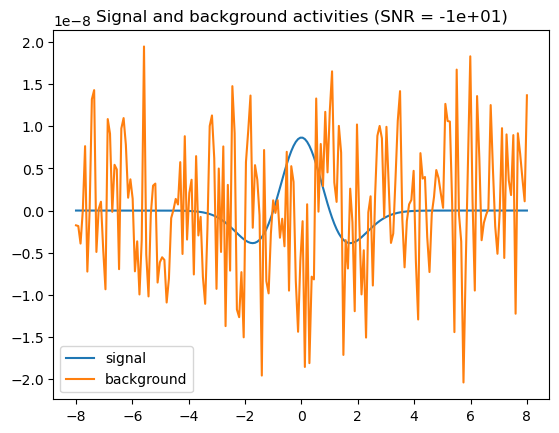

In [ ]:
# signal
wavelet        = pywt.ContinuousWavelet("mexh")
[signal, time] = wavelet.wavefun(level=5, length=int(sfreq*duration))
signal         = signal*10**(-8)    # scale to nA

# relate source SNR to background variance (specific to gaussian background)
Ps  = np.sum((signal - signal.mean())**2)/len(signal)         # Average power of 1 active dipole
a   = 1/(1-(1/len(signal)))                                   # coefficient linking variance to power
b   = (np.sum(roi_mask)**2 * Ps)/(np.sum(~roi_mask) * a)      # coefficient linking target snr to source variance
std = np.sqrt(b * 10**(-s_snr/10))

# background dipoles
brain_activity = np.random.normal(scale=std, size=(data["fwd_hr"]["nsource"], int(data["eeg_coreg"].info["sfreq"])))        # make it brown signal

# active dipoles
brain_activity[roi_mask] = signal

# snr
snr   = mm.utils.compute_snr(brain_activity[roi_mask][0,:], brain_activity[~roi_mask][0,:])                              # signal/background snr
s_snr = mm.utils.compute_snr(np.sum(brain_activity[roi_mask,:], axis=0), np.sum(brain_activity[~roi_mask,:], axis=0))    # source snr

# plot
ax1 = sns.lineplot(x=time, y=brain_activity[roi_mask][0,:], label="signal")
ax2 = sns.lineplot(x=time, y=brain_activity[~roi_mask,:][0,:], label="background")
_   = ax1.set_title(f"Signal and background activities (SNR = {snr[0]:.2})")

#### 🌟 Visualize ground truth

In [282]:
# generate ground truth
vertices     = [data["fwd_hr"]["src"][0]["vertno"], data["fwd_hr"]["src"][1]["vertno"]]
brain_signal = mne.SourceEstimate(brain_activity, vertices, tmin=0, tstep=1/sfreq, subject=sub)

# plot
print(f"Source SNR: {s_snr[0]:.2}")
mm.viz.plot_brain_time_series(data["fwd_hr"]["src"], brain_signal.data, sfreq=sfreq)

Source SNR: -9.9


Widget(value='<iframe src="http://localhost:36261/index.html?ui=P_0x757870b0da90_45&reconnect=auto" class="pyv…

#### ⚙️ <font color=green> Project ground truth to EEG electrodes </font>

In [265]:
eeg     = mne.apply_forward(data["fwd_hr"], brain_signal, data["eeg_coreg"].info, verbose="warning")
eeg_snr = mm.utils.compute_eeg_snr(brain_signal, data["fwd_hr"], roi_mask)

#### 🌟 Visualize EEG

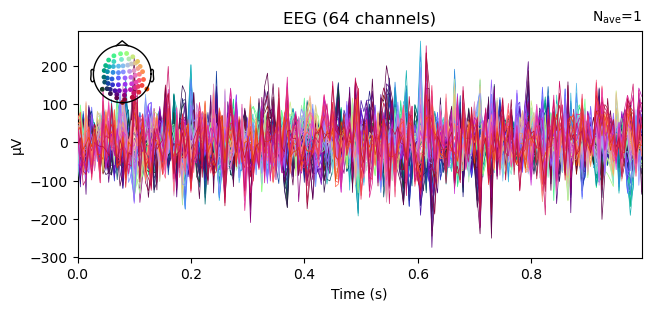

In [266]:
#%matplotlib qt
_ = eeg.plot()

SNR topomap
Minimum SNR: -60.446045654203786
Maximum SNR: -5.092608934170784


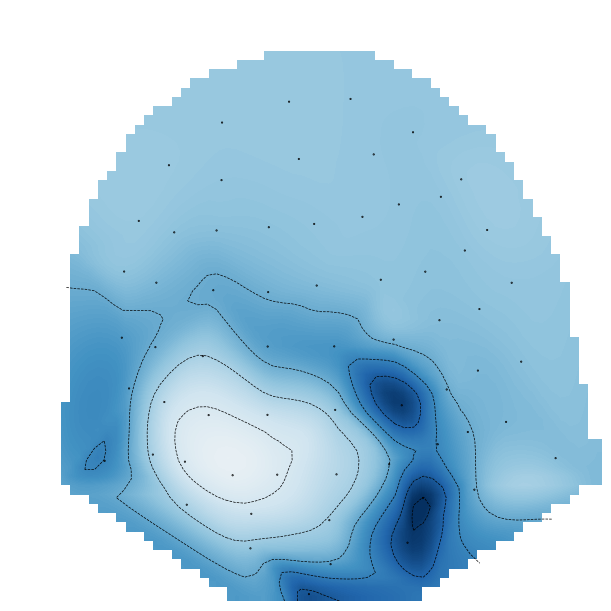

In [267]:
print(f"SNR topomap")
print(f"Minimum SNR: {np.min(eeg_snr)}")
print(f"Maximum SNR: {np.max(eeg_snr)}")
_ = mne.viz.plot_topomap(eeg_snr, data["eeg_coreg"].info, size=6, outlines=None, extrapolate="local")

## Section 2: Model Evaluation
🚨 Run cell '📦 imports' and '🧠 data' before continuing. 

Run the model multiple times for various patch sizes and background variations.

#### 🛠️ <font color=violet>Select loop parameters</font>

In [9]:
rg_s_snr     = [-10, 10]   # range for the SNR in the sources (sum of signal over sum of background)
rg_n_dipoles = [20, 100]   # range for the number of active dipoles
rep          = 3000        # number of repetition

#### Preparing data

In [10]:
# storage
source_snr = np.zeros(rep)                                        # source SNR (sum of signal over sum of background)
eeg_snr    = np.zeros((rep, len(data["eeg_coreg"].ch_names)))     # eeg SNR (1 SNR per electrode)

# vertno (to select dipole and instanciate mne.SourceEstimate)
vertno = [data["fwd_hr"]["src"][0]["vertno"], data["fwd_hr"]["src"][1]["vertno"]]

# dipole distance matrix (to grow dipole patch)
dist = [
    data["fwd_hr"]["src"][0]["dist"][vertno[0]][:,vertno[0]], 
    data["fwd_hr"]["src"][1]["dist"][vertno[1]][:,vertno[1]],
]

# signal (for active dipoles)
wavelet     = pywt.ContinuousWavelet("mexh")
[signal, _] = wavelet.wavefun(level=5, length=int(sfreq*duration))
signal      = signal*10**(-7)

# function relating source SNR to background variance (specific to gaussian background)
Ps  = np.sum((signal - signal.mean())**2)/len(signal)         # Average power of 1 active dipole
a   = 1/(1-(1/len(signal)))                                   # coefficient linking variance to power

compute_std = lambda snr, roi_mask: np.sqrt((np.sum(roi_mask)**2 * Ps)/(np.sum(~roi_mask) * a) * 10**(-snr/10))

#### ⚙️ <font color=green>Loop through simulations</font>

In [11]:
for i in range(rep):
    # select state
    s_snr = np.random.uniform(rg_s_snr[0], rg_s_snr[1])
    n     = np.random.randint(rg_n_dipoles[0], rg_n_dipoles[1])

    # generate patch
    hemi            = np.random.choice([0,1])                    # choose hemisphere (left or right)
    starting_dipole = np.random.choice(vertno[hemi])             # choose starting dipole
    starting_idx    = np.argwhere(vertno[hemi]==starting_dipole)[0]
    
    ddist = dist[hemi][starting_idx].todense().squeeze()    # distance between dipoles and selected dipole
    roi   = np.argsort(ddist)[:n]                           # choose n closest dipoles (includes selected dipole)
    
    if hemi == 1: 
        roi = roi + data["fwd_hr"]["src"][0]["nuse"]     # roi index of right hemisphere start after left hemisphere

    roi_mask = np.zeros(data["fwd_hr"]["nsource"], dtype=bool)
    roi_mask[roi] = True
    
    # generate background
    std            = compute_std(s_snr, roi_mask)
    brain_activity = np.random.normal(scale=std, size=(data["fwd_hr"]["nsource"], int(data["eeg_coreg"].info["sfreq"])))      # make it brown signal

    # generate ground truth
    brain_activity[roi] = signal
    brain_activity      = mne.SourceEstimate(brain_activity, vertno, tmin=0, tstep=1/sfreq, subject=sub)

    # store number of dipole, source snr and eeg snr
    source_snr[i] = mm.utils.compute_snr(np.sum(brain_activity.data[roi_mask,:], axis=0), np.sum(brain_activity.data[~roi_mask,:], axis=0))[0]
    eeg_snr[i,:]  = mm.utils.compute_eeg_snr(brain_activity, data["fwd_hr"], roi_mask)

#### 🌟 Visualize distributions

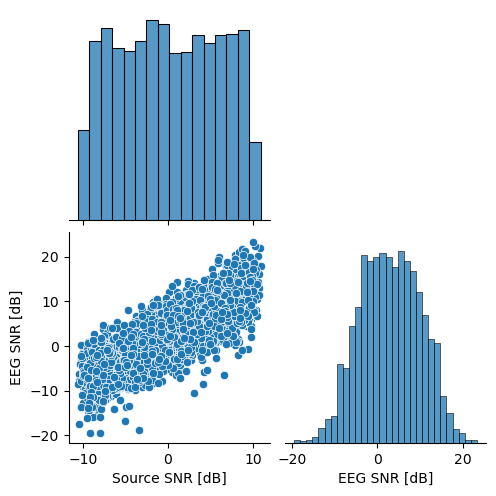

In [12]:
eeg_snr_max = np.max(eeg_snr, axis=1)
eeg_ok      = (eeg_snr_max>0) & (eeg_snr_max<10)
results     = pd.DataFrame({"Source SNR [dB]":source_snr, "EEG SNR [dB]":eeg_snr_max, f"EEG SNR between [{0},{10}]": eeg_ok})

_  = sns.pairplot(
    results, 
    x_vars = ["Source SNR [dB]", "EEG SNR [dB]"],
    y_vars = ["Source SNR [dB]","EEG SNR [dB]"],
    corner = True,
    #height = 200,
    #width  = 200,
)

#### 🌟 Visualize 3D scatter of EEG SNR

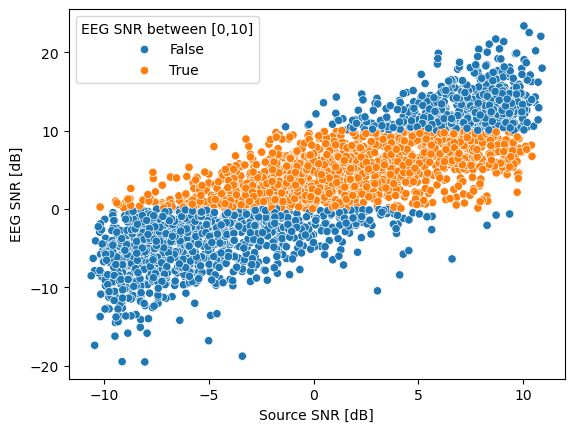

In [13]:
_ = sns.scatterplot(results, x="Source SNR [dB]", y="EEG SNR [dB]", hue="EEG SNR between [0,10]")

In [94]:
# test hypothesis 

# signal
wavelet        = pywt.ContinuousWavelet("mexh")
[signal, time] = wavelet.wavefun(level=5, length=int(sfreq*duration))

# background dipoles
brain_activity = np.random.normal(scale=0.1, size=(data["fwd_hr"]["nsource"], int(data["eeg_coreg"].info["sfreq"])))

# active dipoles
brain_activity[roi_mask] = signal

# generate ground truth
vertices     = [data["fwd_hr"]["src"][0]["vertno"], data["fwd_hr"]["src"][1]["vertno"]]
brain_signal = mne.SourceEstimate(brain_activity, vertices, tmin=0, tstep=1/sfreq, subject=sub)

# project to EEG
eeg     = mne.apply_forward(data["fwd_hr"], brain_signal, data["eeg_coreg"].info, verbose="warning")
eeg_snr = mm.utils.compute_eeg_snr(brain_signal, data["fwd_hr"], roi_mask)

idx = np.argmax(eeg_snr)
print(np.max(eeg_snr))

11.715168662837495


/tmp/ipykernel_12870/2661776959.py:18: RuntimeWarning: The maximum current magnitude is 865223932.7 nAm, which is very large. Are you trying to apply the forward model to noise-normalized (dSPM, sLORETA, or eLORETA) values? The result will only be correct if currents (in units of Am) are used.
  eeg     = mne.apply_forward(data["fwd_hr"], brain_signal, data["eeg_coreg"].info, verbose="warning")


In [95]:
# power/variance coefficient
q = (len(signal)-1)/len(signal)

# covariance matrices
cov_act  = q*np.cov(brain_activity[roi_mask])
cov_back = q*np.cov(brain_activity[~roi_mask])

A = mne.convert_forward_solution(data["fwd_hr"], force_fixed=True, verbose="warning")
A = A["sol"]["data"]

# lead field vector
lfv = A[idx,:]
Pa  = lfv[roi_mask] @ cov_act @ lfv[roi_mask]
Pb  = lfv[~roi_mask] @ cov_back @ lfv[~roi_mask]

print(10*np.log10(Pa/Pb))

11.715168662837494
